### 2(a) Distance, Similarity, K-Means and Hierarchical Clustering

**Aim:** To calculate distances and similarities, implement K-means and Hierarchical Clustering, and visualize hierarchical relationships using a dendrogram.

**Theory:**

- **Euclidean Distance:** Measures the straight-line distance between two data points.
- **Cosine Similarity:** Measures the cosine of the angle between two vectors.
- **K-Means Clustering:** Groups data into K clusters by minimizing the within-cluster sum of squared distances.
- **Hierarchical Clustering:** Builds a hierarchy of clusters by repeatedly merging or splitting groups.
- **Dendrogram:** A tree-like diagram that shows how clusters are merged at different distances.
- **Linkage Methods:** Define how the distance between clusters is calculated. Examples include single, complete, average, and Ward linkage.

**Evaluation Metric:** Silhouette score.

**Dataset:** Generated sample data containing three clusters.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs
from sklearn.metrics import pairwise_distances, silhouette_score
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram

In [2]:
X, _ = make_blobs(n_samples=250, centers=3, cluster_std=1.1, random_state=42)
print("Euclidean distance matrix (first 5 samples):")
print(np.round(pairwise_distances(X[:5], metric="euclidean"), 2))
print("Cosine similarity matrix (first 5 samples):")
print(np.round(cosine_similarity(X[:5]), 2))

Euclidean distance matrix (first 5 samples):
[[ 0.    9.22  9.63  0.11 16.96]
 [ 9.22  0.    2.03  9.26 14.63]
 [ 9.63  2.03  0.    9.65 16.65]
 [ 0.11  9.26  9.65  0.   17.06]
 [16.96 14.63 16.65 17.06  0.  ]]
Cosine similarity matrix (first 5 samples):
[[ 1.    0.3   0.33  1.   -0.5 ]
 [ 0.3   1.    1.    0.31 -0.98]
 [ 0.33  1.    1.    0.33 -0.98]
 [ 1.    0.31  0.33  1.   -0.5 ]
 [-0.5  -0.98 -0.98 -0.5   1.  ]]


In [3]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X)
hier = AgglomerativeClustering(n_clusters=3, linkage="ward")
hier_labels = hier.fit_predict(X)
print("K-means silhouette score:", round(silhouette_score(X, kmeans_labels), 4))
print("Hierarchical silhouette score:", round(silhouette_score(X, hier_labels), 4))

K-means silhouette score: 0.8308
Hierarchical silhouette score: 0.8308


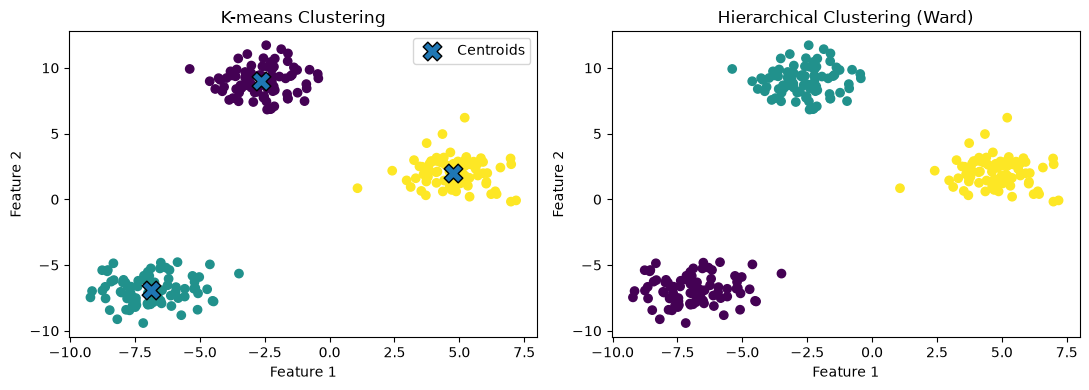

In [4]:
# Graph: compare K-means and hierarchical clusters
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(X[:, 0], X[:, 1], c=kmeans_labels)
axes[0].scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
                marker="X", s=180, edgecolor="black", label="Centroids")
axes[0].set_title("K-means Clustering")
axes[0].legend()
axes[1].scatter(X[:, 0], X[:, 1], c=hier_labels)
axes[1].set_title("Hierarchical Clustering (Ward)")
for ax in axes:
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
plt.tight_layout()
plt.show()

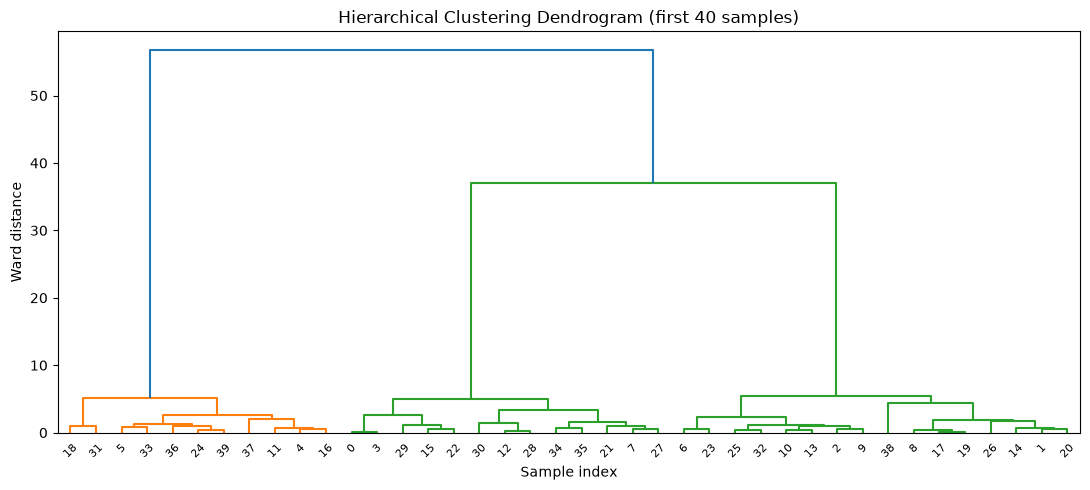

In [5]:
# Dendrogram on a subset so labels remain readable
Z = linkage(X[:40], method="ward")
plt.figure(figsize=(11, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram (first 40 samples)")
plt.xlabel("Sample index")
plt.ylabel("Ward distance")
plt.tight_layout()
plt.show()

**Result and Conclusion:**

K-means and Hierarchical Clustering were implemented on generated sample data. Euclidean distances and cosine similarities were calculated, and a dendrogram was plotted to visualize hierarchical relationships.

The clusters were visualized, and their quality was compared using the silhouette score. A higher silhouette score generally indicates better-separated clusters.